In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

In [59]:
columns = (    
    ['engine_id', 'cycle']    
    + [f'op_setting_{i}' for i in range(1, 4)]    
    + [f'sensor_{i}' for i in range(1, 22)]    
)    


In [60]:
path = "../Dataset/Raw"

# FD002

In [61]:
train_fd2 = pd.read_csv(path + "/train_FD002.txt", sep=r'\s+', header=None, names=columns)    
test_fd2  = pd.read_csv(path + "/test_FD002.txt",  sep=r'\s+', header=None, names=columns)    
rul_fd2   = pd.read_csv(path + "/RUL_FD002.txt",   sep=r'\s+', header=None, names=['actual_RUL'])    

# FD004

In [62]:
train_fd4 = pd.read_csv(path + "/train_FD004.txt", sep=r'\s+', header=None, names=columns)    
test_fd4  = pd.read_csv(path + "/test_FD004.txt",  sep=r'\s+', header=None, names=columns)    
rul_fd4   = pd.read_csv(path + "/RUL_FD004.txt",   sep=r'\s+', header=None, names=['actual_RUL'])    

In [63]:
print(f"FD002 Train: {train_fd2.shape} | Engines: {train_fd2['engine_id'].nunique()}")
print(f"FD002 Test:  {test_fd2.shape}  | Engines: {test_fd2['engine_id'].nunique()} | RUL labels: {len(rul_fd2)}")
print(f"FD004 Train: {train_fd4.shape} | Engines: {train_fd4['engine_id'].nunique()}")
print(f"FD004 Test:  {test_fd4.shape}  | Engines: {test_fd4['engine_id'].nunique()} | RUL labels: {len(rul_fd4)}")

FD002 Train: (53759, 26) | Engines: 260
FD002 Test:  (33991, 26)  | Engines: 259 | RUL labels: 259
FD004 Train: (61249, 26) | Engines: 249
FD004 Test:  (41214, 26)  | Engines: 248 | RUL labels: 248


# Dataset Overview

In [64]:
def inspect_dataset_summary(train_df, test_df, rul_df, name="FD002"):
    train_lifespans = train_df.groupby('engine_id')['cycle'].max()
    test_cutoffs    = test_df.groupby('engine_id')['cycle'].max()
    
    summary = {
        "Dataset": name,
        "Train Engines": train_df['engine_id'].nunique(),
        "Test Engines": test_df['engine_id'].nunique(),
        "Train Total Rows": len(train_df),
        "Test Total Rows": len(test_df),
        "Train Min Lifespan": int(train_lifespans.min()),
        "Train Max Lifespan": int(train_lifespans.max()),
        "Train Mean Lifespan": round(float(train_lifespans.mean()), 1),
        "Test Mean End Cycle": round(float(test_cutoffs.mean()), 1),
        "Test Ground Truth RUL (Mean)": round(float(rul_df['actual_RUL'].mean()), 1),
        "Missing Values": int(train_df.isnull().sum().sum())
    }
    return pd.DataFrame([summary])

summary_fd2 = inspect_dataset_summary(train_fd2, test_fd2, rul_fd2, "FD002")
summary_fd4 = inspect_dataset_summary(train_fd4, test_fd4, rul_fd4, "FD004")
summary_table = pd.concat([summary_fd2, summary_fd4], ignore_index=True)

In [65]:
summary_table

,Dataset,Train Engines,Test Engines,Train Total Rows,Test Total Rows,Train Min Lifespan,Train Max Lifespan,Train Mean Lifespan,Test Mean End Cycle,Test Ground Truth RUL (Mean),Missing Values
0,FD002,260,259,53759,33991,128,378,206.8,131.2,81.2,0
1,FD004,249,248,61249,41214,128,543,246.0,166.2,86.6,0


# The Critical Difference: 6 Operating Conditions

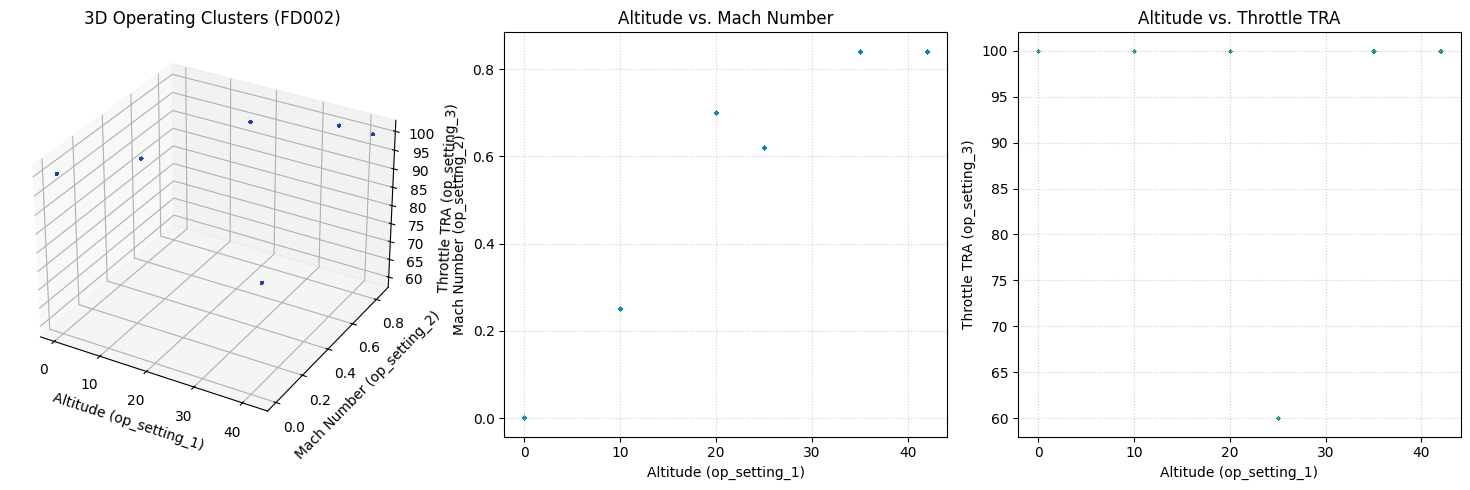

In [66]:
# Visualize the 6 operating regimes in 3D and 2D projections
fig = plt.figure(figsize=(15, 5))

# Subplot 1: 3D flight envelope scatter
ax1 = fig.add_subplot(131, projection='3d')
ax1.scatter(
    train_fd2['op_setting_1'],
    train_fd2['op_setting_2'],
    train_fd2['op_setting_3'],
    c='#1E40AF', alpha=0.03, s=2
)
ax1.set_xlabel('Altitude (op_setting_1)')
ax1.set_ylabel('Mach Number (op_setting_2)')
ax1.set_zlabel('Throttle TRA (op_setting_3)')
ax1.set_title('3D Operating Clusters (FD002)')

# Subplot 2: Altitude vs Mach
ax2 = fig.add_subplot(132)
ax2.scatter(train_fd2['op_setting_1'], train_fd2['op_setting_2'], c='#0284C7', alpha=0.03, s=2)
ax2.set_xlabel('Altitude (op_setting_1)')
ax2.set_ylabel('Mach Number (op_setting_2)')
ax2.set_title('Altitude vs. Mach Number')
ax2.grid(True, linestyle=':', alpha=0.6)

# Subplot 3: Altitude vs Throttle
ax3 = fig.add_subplot(133)
ax3.scatter(train_fd2['op_setting_1'], train_fd2['op_setting_3'], c='#0D9488', alpha=0.03, s=2)
ax3.set_xlabel('Altitude (op_setting_1)')
ax3.set_ylabel('Throttle TRA (op_setting_3)')
ax3.set_title('Altitude vs. Throttle TRA')

ax3.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


# Compute the RUL Target

In [67]:
# For run-to-failure training data, true Remaining Useful Life (RUL)
# is calculated as: RUL(t) = max_cycle - cycle(t)
for df in [train_fd2, train_fd4]:
    df['max_cycle'] = df.groupby('engine_id')['cycle'].transform('max')
    df['RUL'] = df['max_cycle'] - df['cycle']

print("FD002 Training RUL Target Statistics:")
print(train_fd2['RUL'].describe())

print("\nFD004 Training RUL Target Statistics:")
print(train_fd4['RUL'].describe())


FD002 Training RUL Target Statistics:
count    53759.000000
mean       108.154746
std         69.180569
min          0.000000
25%         51.000000
50%        103.000000
75%        156.000000
max        377.000000
Name: RUL, dtype: float64

FD004 Training RUL Target Statistics:
count    61249.000000
mean       133.311417
std         89.783389
min          0.000000
25%         61.000000
50%        122.000000
75%        190.000000
max        542.000000
Name: RUL, dtype: float64


In [68]:
train_fd4

,engine_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,max_cycle,RUL
0,1,1,42.0049,0.8400,100.0,445.00,549.68,1343.43,1112.93,3.91,...,8074.83,9.3335,0.02,330,2212,100.00,10.62,6.3670,321,320
1,1,2,20.0020,0.7002,100.0,491.19,606.07,1477.61,1237.50,9.35,...,8046.13,9.1913,0.02,361,2324,100.00,24.37,14.6552,321,319
2,1,3,42.0038,0.8409,100.0,445.00,548.95,1343.12,1117.05,3.91,...,8066.62,9.4007,0.02,329,2212,100.00,10.48,6.4213,321,318
3,1,4,42.0000,0.8400,100.0,445.00,548.70,1341.24,1118.03,3.91,...,8076.05,9.3369,0.02,328,2212,100.00,10.54,6.4176,321,317
4,1,5,25.0063,0.6207,60.0,462.54,536.10,1255.23,1033.59,7.05,...,7865.80,10.8366,0.02,305,1915,84.93,14.03,8.6754,321,316
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61244,249,251,9.9998,0.2500,100.0,489.05,605.33,1516.36,1315.28,10.52,...,8185.69,8.4541,0.03,372,2319,100.00,29.11,17.5234,255,4
61245,249,252,0.0028,0.0015,100.0,518.67,643.42,1598.92,1426.77,14.62,...,8185.47,8.2221,0.03,396,2388,100.00,39.38,23.7151,255,3
61246,249,253,0.0029,0.0000,100.0,518.67,643.68,1607.72,1430.56,14.62,...,8193.94,8.2525,0.03,395,2388,100.00,39.78,23.8270,255,2
61247,249,254,35.0046,0.8400,100.0,449.44,555.77,1381.29,1148.18,5.48,...,8125.64,9.0515,0.02,337,2223,100.00,15.26,9.0774,255,1


# Sensor Variance Analysis

In [69]:
# Identify non-informative constant sensors
sensor_columns = [f'sensor_{i}' for i in range(1, 22)]
global_variance = train_fd2[sensor_columns].var().sort_values()
print("Global Sensor Variances (FD002):")
print(global_variance)

Global Sensor Variances (FD002):
sensor_16         0.000022
sensor_10         0.016248
sensor_15         0.561504
sensor_11        10.448229
sensor_5         13.059831
sensor_19        28.773210
sensor_6         29.504469
sensor_21        35.065527
sensor_20        97.403698
sensor_1        696.416652
sensor_17       770.313126
sensor_2       1390.499279
sensor_14      7197.477708
sensor_3      11224.627089
sensor_4      14190.391000
sensor_13     16401.482048
sensor_12     18950.139854
sensor_8      21085.890683
sensor_18     21120.221812
sensor_7      21317.549421
sensor_9     112769.707858
dtype: float64


In [70]:
# Standard 14 informative sensors for C-MAPSS
selected_sensors = [
    'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8',
    'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14',
    'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'
]

constant_sensors = [s for s in sensor_columns if s not in selected_sensors]
print(f"\nConstant / Invariant Sensors Dropped (7):\n {constant_sensors}")
print(f"\nInformative Degradation Sensors Retained (14):\n {selected_sensors}")


Constant / Invariant Sensors Dropped (7):
 ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Informative Degradation Sensors Retained (14):
 ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


# Visualizations to Create

# 1. 3D Scatter Plot of Operating Conditions

Text(0.5, 0, 'Throttle')

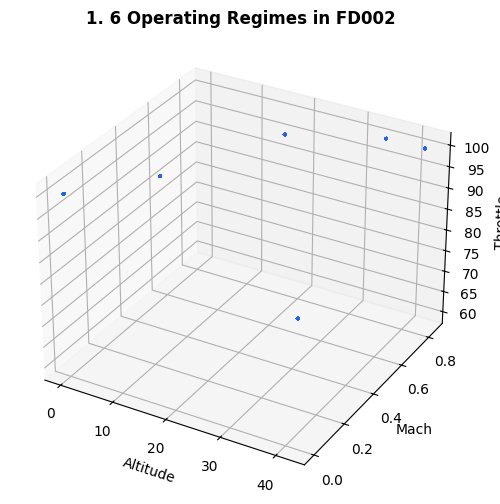

In [71]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(train_fd2['op_setting_1'], train_fd2['op_setting_2'], train_fd2['op_setting_3'],
           c='#2563EB', alpha=0.03, s=2)
ax.set_title("1. 6 Operating Regimes in FD002", fontsize=12, fontweight='bold')
ax.set_xlabel('Altitude'); ax.set_ylabel('Mach'); ax.set_zlabel('Throttle')

# 2. RUL Distribution Histogram (FD002 vs FD004)

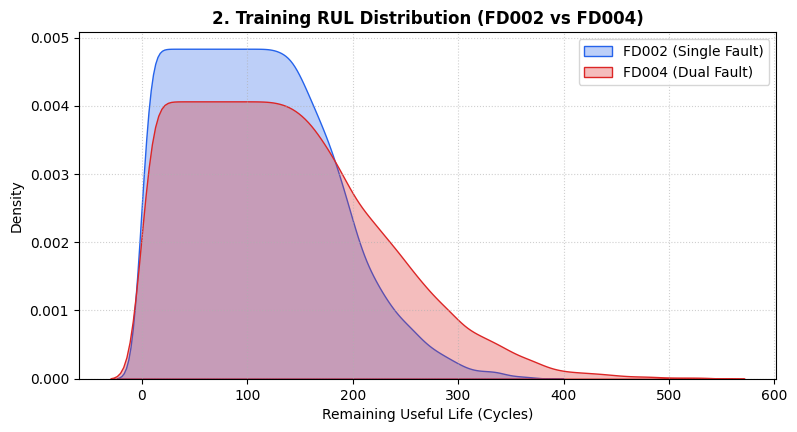

In [72]:
plt.figure(figsize=(9, 4.5))
sns.kdeplot(train_fd2['RUL'], label='FD002 (Single Fault)', color='#2563EB', fill=True, alpha=0.3)
sns.kdeplot(train_fd4['RUL'], label='FD004 (Dual Fault)', color='#DC2626', fill=True, alpha=0.3)
plt.title("2. Training RUL Distribution (FD002 vs FD004)", fontsize=12, fontweight='bold')
plt.xlabel("Remaining Useful Life (Cycles)"); plt.ylabel("Density")
plt.legend(); plt.grid(True, linestyle=':', alpha=0.6)

# 3. Engine Life Distribution Histogram

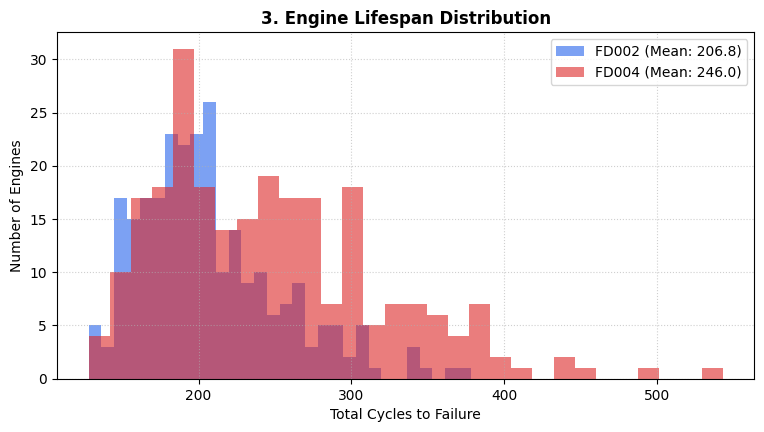

In [73]:
plt.figure(figsize=(9, 4.5))
max_c_fd2 = train_fd2.groupby('engine_id')['cycle'].max()
max_c_fd4 = train_fd4.groupby('engine_id')['cycle'].max()
plt.hist(max_c_fd2, bins=30, alpha=0.6, color='#2563EB', label=f'FD002 (Mean: {max_c_fd2.mean():.1f})')
plt.hist(max_c_fd4, bins=30, alpha=0.6, color='#DC2626', label=f'FD004 (Mean: {max_c_fd4.mean():.1f})')
plt.title("3. Engine Lifespan Distribution", fontsize=12, fontweight='bold')
plt.xlabel("Total Cycles to Failure"); plt.ylabel("Number of Engines")
plt.legend(); plt.grid(True, linestyle=':', alpha=0.6)

#  4. Sensor Degradation Trends (FD002) - Raw Signal Jumps

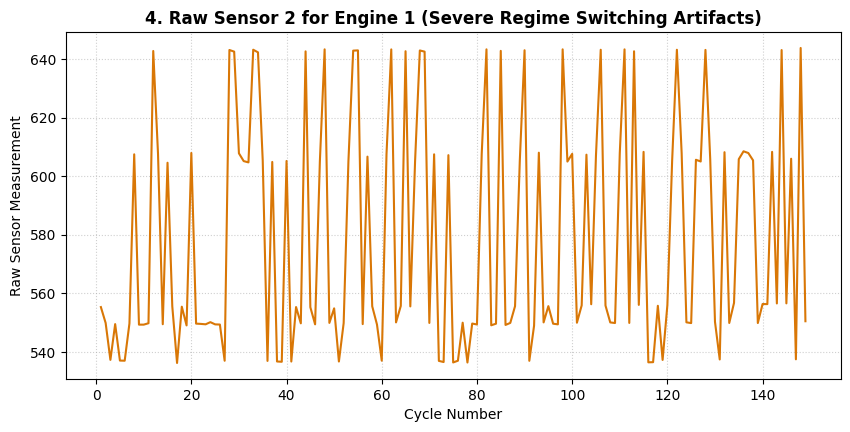

In [74]:
sample_engine = train_fd2[train_fd2['engine_id'] == 1]
plt.figure(figsize=(10, 4.5))
plt.plot(sample_engine['cycle'], sample_engine['sensor_2'], color='#D97706', lw=1.5)
plt.title("4. Raw Sensor 2 for Engine 1 (Severe Regime Switching Artifacts)", fontsize=12, fontweight='bold')
plt.xlabel("Cycle Number"); plt.ylabel("Raw Sensor Measurement")
plt.grid(True, linestyle=':', alpha=0.6)

# 5. Sensor Degradation Trends (Per Regime) - Clean Monotonic Wear

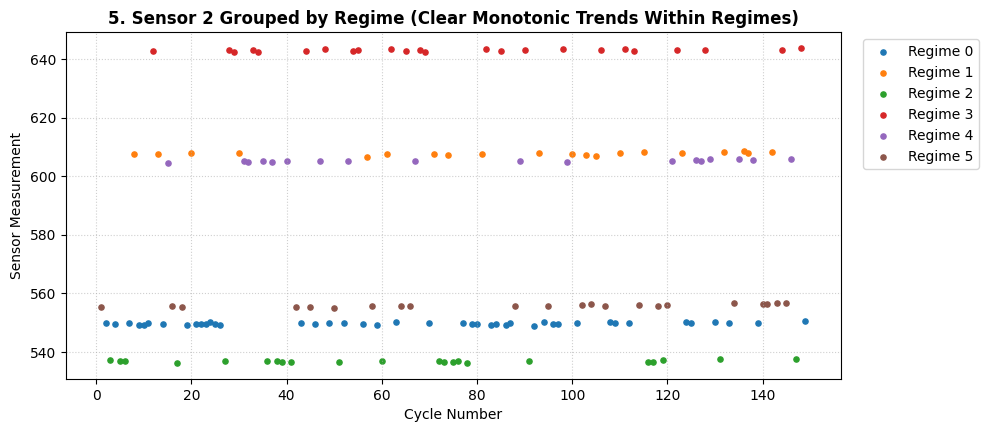

In [75]:
km_temp = KMeans(n_clusters=6, random_state=42, n_init=10)
train_fd2['temp_regime'] = km_temp.fit_predict(train_fd2[['op_setting_1', 'op_setting_2', 'op_setting_3']])
sample_engine = train_fd2[train_fd2['engine_id'] == 1]
plt.figure(figsize=(10, 4.5))
for r in range(6):
    r_data = sample_engine[sample_engine['temp_regime'] == r]
    if len(r_data) > 0:
        plt.scatter(r_data['cycle'], r_data['sensor_2'], label=f'Regime {r}', s=14)
plt.title("5. Sensor 2 Grouped by Regime (Clear Monotonic Trends Within Regimes)", fontsize=12, fontweight='bold')
plt.xlabel("Cycle Number"); plt.ylabel("Sensor Measurement")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.grid(True, linestyle=':', alpha=0.6)

# 6. Correlation Heatmap Between 14 Selected Sensors and RUL

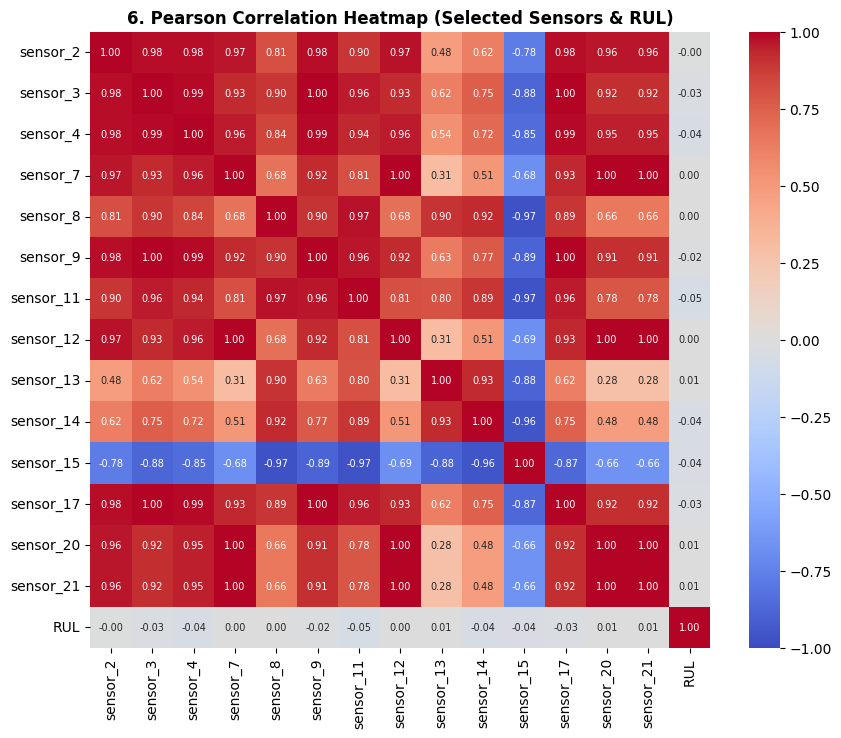

In [76]:
plt.figure(figsize=(10, 8))
corr_matrix = train_fd2[selected_sensors + ['RUL']].corr()
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={"size": 7})
plt.title("6. Pearson Correlation Heatmap (Selected Sensors & RUL)", fontsize=12, fontweight='bold')
plt.show()